In [2]:
from pathlib import Path
import sys

LOCAL_RECTANGLE = Path('/Users/berni/PycharmProjects/Rectangle')
local_src = LOCAL_RECTANGLE / 'src'
if not (local_src / 'rectanglepy' / '__init__.py').is_file():
    raise FileNotFoundError(f'Local Rectangle package not found in {local_src}')
loaded_rectangle = sys.modules.get('rectanglepy')
if loaded_rectangle is not None and not Path(loaded_rectangle.__file__).resolve().is_relative_to(local_src.resolve()):
    raise RuntimeError('rectanglepy is already loaded from another location. Restart the kernel and run this cell first.')
if str(local_src) in sys.path:
    sys.path.remove(str(local_src))
sys.path.insert(0, str(local_src))

import rectanglepy as rp
if not Path(rp.__file__).resolve().is_relative_to(local_src.resolve()):
    raise RuntimeError('rectanglepy was imported from another location. Restart the kernel and run this cell first.')
print('Rectangle source:', rp.__file__, flush=True)
print('Rectangle distribution version:', rp.__version__, flush=True)

Rectangle source: /Users/berni/PycharmProjects/Rectangle/src/rectanglepy/__init__.py
Rectangle distribution version: 1.6.0


In [3]:
# Rectangle on the three Spotless gold standards (as in rectangle_benchmark/spatial_benchmark.py).
# The other methods' metrics are the frozen Spotless results in ../data/fig5/<dataset>/metrics_*;
# Rectangle's are computed here with the local rectanglepy source and replace its frozen ones below.
import re
from pathlib import Path
from zipfile import ZipFile

import anndata
import numpy as np
import pandas as pd
import rectanglepy as rp

GOLD_DIR = Path('../data/fig5/spotless_gold_standards')
SPATIAL_DATASETS = [
    {'standard': 'gold_standard_1', 'dataset': 'Eng2019_cortex_svz', 'reference': 'gold_standard_1.h5ad',
     'samples': [f'Eng2019_cortex_svz_fov{i}' for i in range(7)]},
    {'standard': 'gold_standard_2', 'dataset': 'Eng2019_ob', 'reference': 'gold_standard_2.h5ad',
     'samples': [f'Eng2019_ob_fov{i}' for i in range(7)]},
    {'standard': 'gold_standard_3', 'dataset': 'Wang2018_visp', 'reference': 'gold_standard_3_12celltypes.h5ad',
     'samples': ['Wang2018_visp_rep0410']},
]
spot_ground_truth = pd.read_csv(GOLD_DIR / 'ground_truth.csv')


def _normalise_cell_types(columns, prediction=False):
    # Spotless's metrics.R strips these characters to match predicted and true cell-type names
    pattern = r'[/ .&-]' if prediction else r'[/ .]'
    return [re.sub(pattern, '', str(column)) for column in columns]


def _sample_ground_truth(sample):
    truth = spot_ground_truth.loc[spot_ground_truth['sample'] == sample].sort_values('spot_index')
    value_columns = [c for c in truth.columns
                     if c not in {'standard', 'sample', 'spot_index'} and truth[c].notna().any()]
    truth = truth[value_columns].fillna(0.0).reset_index(drop=True)
    truth.columns = _normalise_cell_types(truth.columns)
    return truth


def _spotless_metrics(truth, estimations):
    """Mean per-spot Pearson correlation and RMSE, as Spotless's subworkflows/evaluation/metrics.R."""
    estimations = estimations.copy()
    estimations.columns = _normalise_cell_types(estimations.columns, prediction=True)
    cell_types = sorted(set(truth.columns) | set(estimations.columns))
    truth = truth.reindex(columns=cell_types, fill_value=0.0).to_numpy()
    estimations = estimations.reindex(columns=cell_types, fill_value=0.0).to_numpy()
    assert truth.shape == estimations.shape, (truth.shape, estimations.shape)
    correlations = [np.corrcoef(t, e)[0, 1] for t, e in zip(truth, estimations)]
    rmse = np.sqrt(np.mean((truth - estimations) ** 2, axis=1))
    return float(np.mean(correlations)), float(np.mean(rmse))


def _spot_number(spot):
    match = re.search(r'(\d+)$', str(spot))
    return (0, int(match.group(1))) if match else (1, str(spot))


rectangle_spatial_rows = []
for config in SPATIAL_DATASETS:
    standard_dir = GOLD_DIR / config['standard']
    if not (standard_dir / config['reference']).exists():
        with ZipFile(GOLD_DIR / f"spatial_{config['standard']}.zip") as archive:
            archive.extractall(standard_dir)

    # Every spot of every sample is one bulk, scaled to counts per million
    sample_bulks = []
    for sample in config['samples']:
        spots = anndata.read_h5ad(standard_dir / f'{sample}.h5ad').to_df()
        assert (spots.sum(axis=1) > 0).all(), f'{sample} contains spots with no counts'
        spots = spots.div(spots.sum(axis=1), axis=0) * 1e6
        spots.index = [f'{sample}::{spot}' for spot in spots.index]
        sample_bulks.append(spots)

    reference = anndata.read_h5ad(standard_dir / config['reference'])
    estimations, _ = rp.rectangle(reference, pd.concat(sample_bulks), cell_type_col='celltype')
    estimations = estimations.drop(columns='Unknown', errors='ignore')

    for sample in config['samples']:
        sample_estimations = estimations.loc[estimations.index.str.startswith(f'{sample}::')].copy()
        sample_estimations.index = sample_estimations.index.str.removeprefix(f'{sample}::')
        sample_estimations = sample_estimations.sort_index(key=lambda index: index.map(_spot_number))
        correlation, rmse = _spotless_metrics(_sample_ground_truth(sample), sample_estimations)
        rectangle_spatial_rows.append({'Set': config['dataset'], 'sample': sample, 'Method': 'rectangle',
                                       'Correlation': correlation, 'RMSE': rmse})

rectangle_spatial_metrics = pd.DataFrame(rectangle_spatial_rows)
rectangle_spatial_metrics.to_csv('../data/fig5/rectangle_spatial_metrics.csv', index=False)
print(f'rectanglepy {rp.__version__}')
rectangle_spatial_metrics.groupby('Set')[['Correlation', 'RMSE']].mean()

2026-10-08 19:26:12.875 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 9969 common genes between bulks and single-cell data
2026-10-08 19:26:12.989 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 19:26:13.940 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astrocytes deep
2026-10-08 19:26:18.714 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astrocytes superficial
2026-10-08 19:26:19.616 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Choroid plexus
2026-10-08 19:26:20.603 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Endothelial
2026-10-08 19:26:21.114 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Ependymal
2026-10-08 19:26:21.220 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE a

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 19:26:41.034 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.04394286798585007, Pearson R:0.7081304988542257 for p=0.05, lfc=1.7
2026-10-08 19:26:41.102 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 61


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 19:26:41.213 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.0440440781889559, Pearson R:0.7080270161879556 for p=0.05, lfc=1.8
2026-10-08 19:26:41.293 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 53
2026-10-08 19:26:41.391 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.045297203557605824, Pearson R:0.6971774602169067 for p=0.05, lfc=1.9
2026-10-08 19:26:41.435 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 37


...

2026-10-08 19:27:35.382 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 68
2026-10-08 19:27:35.389 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 67
2026-10-08 19:27:35.391 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 75
2026-10-08 19:27:35.407 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 76
2026-10-08 19:27:35.500 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 69
2026-10-08 19:27:35.506 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 77
2026-10-08 19:27:35.541 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 70
2026-10-08 19:27:35.545 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 78
2026-10-08 19:27:35.622 | IN

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 19:27:38.127 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 106
2026-10-08 19:27:38.147 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 105
2026-10-08 19:27:38.230 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 107


rectanglepy 1.6.0


,Correlation,RMSE
Set,,
Eng2019_cortex_svz,0.646241,0.097662
Eng2019_ob,0.698314,0.120833
Wang2018_visp,0.585847,0.151050


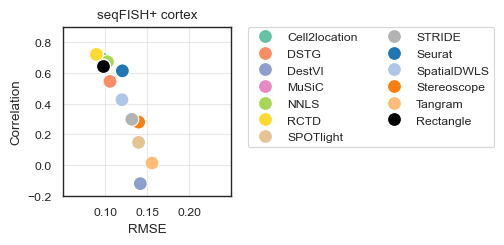

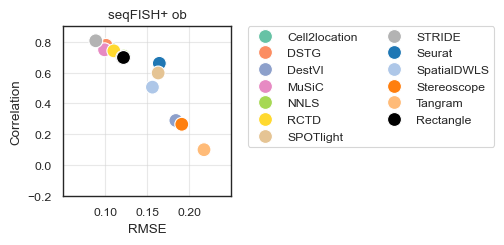

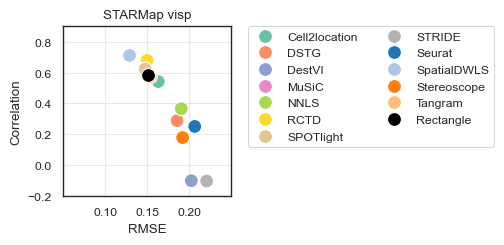

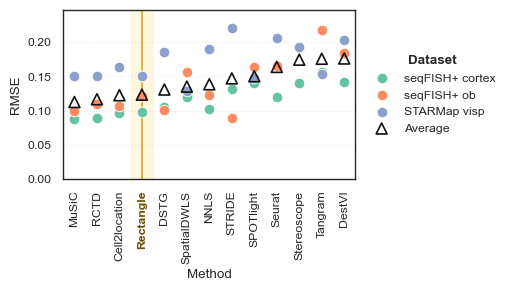

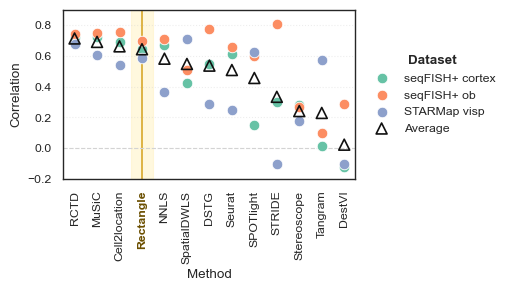

In [4]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator


base_dir = Path("../data/fig5")
datasets = ["Eng2019_cortex_svz", "Eng2019_ob", "Wang2018_visp"]

rows = []
for dataset in datasets:
    dataset_dir = base_dir / dataset
    if dataset == "Wang2018_visp":
        pattern = re.compile(r"metrics_(.+)_Wang2018_visp_.*$")
        glob_pattern = "metrics_*_Wang2018_visp_*"
    else:
        pattern = re.compile(rf"metrics_(.+)_{re.escape(dataset)}_fov\d+$")
        glob_pattern = f"metrics_*_{dataset}_fov*"

    for path in sorted(dataset_dir.glob(glob_pattern)):
        match = pattern.match(path.name)
        if not match:
            continue
        method = match.group(1)
        if method == 'rectangle':
            continue  # Rectangle's metrics are computed in the cell above
        df = pd.read_csv(path, sep=r"\s+", engine="python")
        df.columns = [c.strip('"') for c in df.columns]
        rows.append({
            "Set": dataset,
            "Method": method,
            "Correlation": float(df.loc[0, "corr"]),
            "RMSE": float(df.loc[0, "RMSE"]),
        })

if 'rectangle_spatial_metrics' not in globals():
    rectangle_spatial_metrics = pd.read_csv('../data/fig5/rectangle_spatial_metrics.csv')
rows.extend(rectangle_spatial_metrics[['Set', 'Method', 'Correlation', 'RMSE']].to_dict('records'))

all_meths = pd.DataFrame(rows)
all_meths = (
    all_meths.groupby(["Set", "Method"], as_index=False)
    .agg({"Correlation": "mean", "RMSE": "mean"})
)

all_meths_cortex = all_meths[all_meths['Set'] == 'Eng2019_cortex_svz'].copy()
all_meths_ob = all_meths[all_meths['Set'] == 'Eng2019_ob'].copy()
all_meths_visp = all_meths[all_meths['Set'] == 'Wang2018_visp'].copy()

proper_method_names = {
    "spotlight": "SPOTlight",
    "music": "MuSiC",
    "cell2location": "Cell2location",
    "rctd": "RCTD",
    "stereoscope": "Stereoscope",
    "spatialdwls": "SpatialDWLS",
    "destvi": "DestVI",
    "nnls": "NNLS",
    "dstg": "DSTG",
    "seurat": "Seurat",
    "tangram": "Tangram",
    "stride": "STRIDE",
    "rectangle": "Rectangle"
}

for df in (all_meths_cortex, all_meths_ob, all_meths_visp):
    df['Method'] = df['Method'].map(proper_method_names).fillna(df['Method'])

methods = sorted(all_meths['Method'].unique())
if 'rectangle' in methods:
    methods = [m for m in methods if m != 'rectangle'] + ['rectangle']
methods_display = [proper_method_names.get(m, m) for m in methods]

# alphabetical order for legend, rectangle last
methods_display_no_rect = sorted([m for m in methods_display if m != 'Rectangle'])
methods_display = methods_display_no_rect + ['Rectangle']

# build a palette that scales beyond Set2
base_colors = sns.color_palette("Set2")
needed = len(methods_display_no_rect)
if needed <= len(base_colors):
    colors = base_colors[:needed]
else:
    extra = sns.color_palette("tab20", n_colors=needed - len(base_colors))
    colors = base_colors + extra

palette_display = dict(zip(methods_display_no_rect, colors))
palette_display['Rectangle'] = '#000000'

sns.set_theme(style="white", context="paper")


def plot_dataset(df, title, out_path):
    plt.figure(figsize=(2.5, 2.6))

    # base plot for legend
    sns.scatterplot(
        data=df,
        x='RMSE',
        y='Correlation',
        hue='Method',
        hue_order=methods_display,
        s=100,
        palette=palette_display
    )

    # overlay rectangle last for visibility
    df_rectangle = df[df['Method'] == 'Rectangle']
    if not df_rectangle.empty:
        sns.scatterplot(
            data=df_rectangle,
            x='RMSE',
            y='Correlation',
            hue='Method',
            hue_order=['Rectangle'],
            s=100,
            palette=palette_display,
            legend=False,
            zorder=10
        )

    plt.title(title)
    plt.ylim(-0.2, 0.9)
    plt.xlim(0.05, 0.25)
    plt.xticks([0.1,0.15, 0.2])

    ax = plt.gca()  # <-- define ax here

    # optional: faint minor grid
    ax.grid(which='major', linestyle='-', color='lightgrey')
    plt.tight_layout()
    plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0., ncol=2)
    plt.savefig(out_path, bbox_inches='tight')
    plt.show()

plot_dataset(all_meths_cortex, 'seqFISH+ cortex', '../figures/fig5c_Eng2019_cortex_svz.pdf')
plot_dataset(all_meths_ob, 'seqFISH+ ob', '../figures/fig5c_Eng2019_ob.pdf')
plot_dataset(all_meths_visp, 'STARMap visp', '../figures/fig5c_Wang2018_visp_12celltypes.pdf')


dataset_plot_frames = [
    ('seqFISH+ cortex', all_meths_cortex),
    ('seqFISH+ ob', all_meths_ob),
    ('STARMap visp', all_meths_visp),
]
method_dataset_df = pd.concat(
    [df.assign(Dataset=label) for label, df in dataset_plot_frames],
    ignore_index=True,
)

dataset_order = [label for label, _ in dataset_plot_frames]
dataset_palette = dict(zip(dataset_order, sns.color_palette('Set2', n_colors=len(dataset_order))))
method_dataset_order = [m for m in methods_display if m in set(method_dataset_df['Method'])]


def plot_method_dataset_metric(metric_col, x_label, out_path):
    avg_metric = method_dataset_df.groupby('Method')[metric_col].mean()
    ascending = metric_col == 'RMSE'
    metric_order = (
        avg_metric.reindex(method_dataset_order)
        .sort_values(ascending=ascending)
        .index.tolist()
    )

    fig, ax = plt.subplots(figsize=(6.2, 3.0), facecolor='white')
    ax.set_facecolor('white')

    rectangle_idx = metric_order.index('Rectangle') if 'Rectangle' in metric_order else None
    if rectangle_idx is not None:
        ax.axvspan(rectangle_idx - 0.5, rectangle_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
        ax.axvline(rectangle_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

    x = np.arange(len(metric_order), dtype=float)
    for dataset in dataset_order:
        sub = method_dataset_df[method_dataset_df['Dataset'] == dataset].set_index('Method')
        y_vals = [sub.loc[m, metric_col] if m in sub.index else np.nan for m in metric_order]
        ax.scatter(
            x,
            y_vals,
            s=58,
            marker='o',
            color=dataset_palette[dataset],
            edgecolor='white',
            linewidth=0.6,
            label=dataset,
            zorder=3,
        )

    avg_vals = [avg_metric.loc[m] if m in avg_metric.index else np.nan for m in metric_order]
    ax.scatter(
        x,
        avg_vals,
        s=62,
        marker='^',
        facecolors='none',
        edgecolors='#111111',
        linewidths=1.2,
        label='Average',
        zorder=4,
    )

    if metric_col == 'Correlation':
        ax.axhline(0, linestyle='--', color='lightgrey', linewidth=0.8, zorder=1)
        ax.set_ylim(-0.2, 0.9)
        ax.set_yticks(np.linspace(-0.2, 0.8, 6))
    else:
        metric_max = float(max(method_dataset_df[metric_col].max(skipna=True), avg_metric.max(skipna=True)))
        ax.set_ylim(0, max(metric_max * 1.12, 0.1))

    ax.set_xlim(-0.5, len(metric_order) - 0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_order, rotation=90)
    for lbl, method in zip(ax.get_xticklabels(), metric_order):
        if method == 'Rectangle':
            lbl.set_fontweight('bold')
            lbl.set_color('#6b4f00')

    ax.set_xlabel('Method')
    ax.set_ylabel(x_label)
    ax.grid(axis='y', linestyle=':', alpha=0.35)
    legend = ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False, title='Dataset')
    legend.get_title().set_fontweight('bold')
    plt.tight_layout(rect=[0.0, 0.0, 0.84, 1.0])
    plt.savefig(out_path, facecolor='white', bbox_inches='tight')
    plt.show()


plot_method_dataset_metric('RMSE', 'RMSE', '../figures/fig5c_method_dataset_rmse.pdf')
plot_method_dataset_metric('Correlation', 'Correlation', '../figures/fig5c_method_dataset_correlation.pdf')


##  5b

In [5]:
## 5b

In [6]:
import spatialdata_io
import pandas as pd
import numpy as np
from anndata import AnnData, read_h5ad
import rectanglepy as rectangle
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
s_data = spatialdata_io.visium(path='../data/spatial_ST8059048', dataset_id='ST8059048', scalefactors_file='scalefactors_json.json', tissue_positions_file='tissue_positions_list.csv', counts_file='ST8059048_filtered_feature_bc_matrix.h5')



INFO     reading ../data/spatial_ST8059048/ST8059048_filtered_feature_bc_matrix.h5                                 


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/models/models.py:1144: UserWarning: Converting `region_key: region` to categorical dtype.
  return convert_region_column_to_categorical(adata)


In [7]:
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
adata = read_h5ad('../data/cell2location_single_cell_processed.h5ad')


In [8]:
adata.obs['annotation_1'].value_counts()

annotation_1
Oligo_2           5859
Inh_4              830
Ext_L23            801
Ext_Thal_1         740
Micro              726
Ext_L56            645
Ext_L25            596
Ext_Pir            592
OPC_1              533
Ext_Hpc_DG2        523
Ext_L5_1           510
Inh_1              484
Inh_Pvalb          441
Ext_Hpc_CA1        426
Inh_2              420
Inh_3              414
Ext_Amy_2          406
Ext_Thal_2         383
Inh_Meis2_3        365
Inh_Sst            330
Inh_Vip            285
Oligo_1            285
Ext_L6             281
Inh_Meis2_2        275
Inh_6              264
Astro_THAL_med     243
Ext_Hpc_DG1        240
Astro_CTX          233
Astro_HYPO         232
Astro_AMY_CTX      209
Inh_Meis2_1        207
Ext_Amy_1          190
Astro_AMY          188
Inh_Lamp5          179
Ext_L6B            171
Astro_THAL_lat     168
OPC_2              159
Ext_Hpc_CA3        140
Ext_ClauPyr        131
Astro_HPC          130
Nb_1               126
Astro_WM           124
Ext_L5_2           11

In [9]:
adata.obs['cell_type'].value_counts()


cell_type
Oligo          6144
Inh            2484
Ext_Hpc        1356
Ext_Thal       1123
Inh_Meis2       941
Ext_L23         801
Micro           726
OPC             692
Ext_L5          688
Ext_L56         645
Astro_AMY       630
Ext_L25         596
Ext_Amy         596
Ext_Pir         592
Inh_Pvalb       441
Astro_THAL      439
Inh_Sst         330
Inh_Vip         285
Ext_L6          281
Astro_HYPO      232
Nb              217
Inh_Lamp5       179
Ext_L6B         171
Ext_ClauPyr     131
Astro_HPC       130
Astro_WM        124
Name: count, dtype: int64

adata.obs.value_counts()

In [10]:
data_table = s_data['table']
bulks = data_table.to_df()
bulks_cpm = bulks.div(bulks.sum(axis=1), axis=0) * 1e6

In [11]:
estimations, signature_result = rectangle.rectangle(adata, bulks_cpm)


2026-10-08 19:27:49.811 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 19788 common genes between bulks and single-cell data
2026-10-08 19:27:52.189 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 19:27:54.489 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astro_AMY
2026-10-08 19:27:55.397 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astro_HPC
2026-10-08 19:27:56.437 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astro_HYPO
2026-10-08 19:27:57.416 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astro_THAL
2026-10-08 19:27:58.522 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Astro_WM
2026-10-08 19:27:59.392 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Ext_Amy
/Use

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 19:28:43.740 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.023842060018011056, Pearson R:0.45826187129674867 for p=0.05, lfc=1.6


Polishing not needed - no active set detected at optimal point


2026-10-08 19:28:44.036 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 79
2026-10-08 19:28:44.334 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02390520549198527, Pearson R:0.4575548044291052 for p=0.05, lfc=1.7


...

2026-10-08 19:28:46.791 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 72


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 19:28:47.030 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02462491571475994, Pearson R:0.4457384695490514 for p=0.05, lfc=2.2
2026-10-08 19:28:47.034 | INFO     | rectanglepy.pp.create_signature:_de_analysis:232 - Optimization done
 Best cutoffs  p: 0.05 and lfc: 1.6
2026-10-08 19:28:47.337 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 79
2026-10-08 19:28:47.347 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:385 - Starting rectangle cluster analysis
2026-10-08 19:28:47.377 | INFO     | rectanglepy.pp.create_signature:_create_clustered_data:290 - Starting clustered analysis
2026-10-08 19:28:47.637 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 19:28:49.612 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 13
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-package

Polishing not needed - no active set detected at optimal point


2026-10-08 19:35:35.405 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 780
2026-10-08 19:35:35.422 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 788
2026-10-08 19:35:35.474 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 779
2026-10-08 19:35:35.508 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 789
2026-10-08 19:35:35.852 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 781
2026-10-08 19:35:35.863 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 790
2026-10-08 19:35:37.856 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:446 - Finished deconvolution for bulk: 782
2026-10-08 19:35:37.874 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:440 - Deconvolute fractions for bulk: 791
2026-10-08 19:35:37.

In [12]:
# remove disconnected spots
disconnected_spots = ["AATCGAGGTCTCAAGG-1", "ACCACACGGTTGATGG-1",
                   "ACCGAGTCTCCTTATT-1", "AGCAGTCGAAGCATGC-1",
                   "AGTACAGAAGCTTATA-1", "CCTACAGTTGAGGGAG-1",
                   "CGCTTTCCGCCAAGGT-1", "CGGTATGGGCACTCTG-1",
                   "CGGTTGGGCAGGGTCC-1", "CTATCACAACGCTGGA-1",
                   "CTCTAACACCGGCAGC-1", "CTTACATAGATTTCTT-1",
                   "CTTCATCACCAGGGCT-1", "GAAGGGTCATTAAGAC-1",
                   "GACCACACTTCCCTTT-1", "GCACGCCGATTCCCGC-1",
                   "GCGGCTTTAGCAAGTT-1", "GCGTCGTAACATGGTC-1",
                   "GGATTAATCATGGACC-1", "GTACTACGGCCTCGTT-1",
                   "TACACAGCCGTGGTGC-1", "TCAGCGCACGCCGTTT-1",
                   "TGCCCGATAGTTAGAA-1", "TGTAGCCAATTCCGTT-1"]
estimations = estimations.drop(index=disconnected_spots)

In [13]:
estimations.to_csv('../data/fig5/rectangle_ST8059048_estimations.csv')

## Figure 5A: spatial map

INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata_plot/pl/basic.py:962: UserWarning: Converting copy of 'is_bad' column to categorical dtype for categorical plotting. Consider converting before plotting.
  _render_shapes(


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


...

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


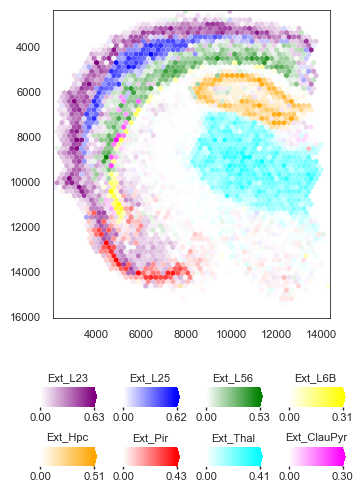

In [14]:
# Figure 5A: spatial map of Rectangle's excitatory-neuron fractions on Visium ST8059048
# (ported from spatial_visualisation.ipynb). Each spot shows only its most abundant of the eight
# displayed cell types, coloured by that cell type's fraction.
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spatialdata as sd
import spatialdata_plot  # noqa: F401  (registers sdata.pl)
from anndata import AnnData
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize
from matplotlib.ticker import AutoLocator
from spatialdata.models import TableModel

SPATIAL_CELL_TYPE_COLORS = {
    'Ext_L23': 'Purple',
    'Ext_L25': 'Blue',
    'Ext_L56': 'Green',
    'Ext_L6B': 'Yellow',
    'Ext_Hpc': 'Orange',
    'Ext_Pir': 'Red',
    'Ext_Thal': 'Cyan',
    'Ext_ClauPyr': 'Magenta',
}

spatial_sdata = sd.read_zarr('../data/ST8059048.zarr')
spatial_counts = spatial_sdata['table'].to_df().sum(axis=1)
spatial_estimations = pd.read_csv('../data/fig5/rectangle_ST8059048_estimations.csv', index_col=0)
# Spots with fewer than 500 counts are not shown
spatial_estimations = spatial_estimations.drop(index=spatial_counts.index[spatial_counts < 500], errors='ignore')


def transparent_sequential_cmap(color, n=256, name=None):
    """Colormap from white to ``color`` where 0 is fully transparent."""
    target = np.array(mpl.colors.to_rgb(color), dtype=float)
    t = np.linspace(0.0, 1.0, n)
    rgb = (1.0 - t)[:, None] * np.ones(3)[None, :] + t[:, None] * target[None, :]
    return mpl.colors.ListedColormap(np.concatenate([rgb, t[:, None]], axis=1), name or f'{color}_transparent_seq')


def _keep_most_likely_cell_type(fractions):
    # Per spot keep only the largest fraction, set the others to 0
    values = fractions.to_numpy()
    winners = np.zeros_like(values)
    rows = np.arange(values.shape[0])
    winners[rows, values.argmax(axis=1)] = values[rows, values.argmax(axis=1)]
    return pd.DataFrame(winners, index=fractions.index, columns=fractions.columns)


def add_rectangle_results_to_spatialdata(sdata, estimations, cell_types, table_name='rectangle_results',
                                         region_name='ST8059048', source_table='table'):
    table = TableModel.parse(AnnData(_keep_most_likely_cell_type(estimations[cell_types])))
    spot_ids = table.obs.merge(sdata.tables[source_table].obs, left_index=True, right_index=True, how='left')
    good = spot_ids.index[~np.isnan(spot_ids['spot_id'].values)]
    table = table[good, :].copy()
    table.uns['spatialdata_attrs'] = {'region': region_name, 'region_key': 'region', 'instance_key': 'spot_id'}
    table.obs['region'] = pd.Categorical([region_name] * len(table))
    table.obs['spot_id'] = spot_ids.loc[good, 'spot_id'].values.astype(int)
    sdata.tables[table_name] = table
    sdata.tables[table_name].X = sdata.tables[table_name].to_df().fillna(0).values


def add_celltype_colorbar(ax, values, cmap, name, bar_y=0.12, bar_h=0.45):
    values = np.asarray(values, float)
    values = values[~np.isnan(values)]
    vmax = float(values.max()) if values.size and values.max() > 0 else 1.0
    opaque = cmap(np.linspace(0.0, 1.0, 256))
    opaque[:, 3] = 1.0
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    bar_ax = ax.inset_axes([0.02, bar_y, 0.96, bar_h])
    cbar = ColorbarBase(bar_ax, cmap=mpl.colors.ListedColormap(opaque), norm=Normalize(vmin=0.0, vmax=vmax),
                        orientation='horizontal', extend='both', extendfrac=0.05)
    cbar.set_ticks([0.0, vmax])
    cbar.set_ticklabels(['0.00', f'{vmax:.2f}'])
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(labelsize=8, length=2, pad=2)
    for spine in bar_ax.spines.values():
        spine.set_edgecolor('white')
        spine.set_linewidth(0.75)
    ax.text(0.5, bar_y + bar_h + 0.10, name, ha='center', va='bottom', fontsize=8, transform=ax.transAxes)


def draw_spatial_panel(fig, subplot_spec, height_ratios=(3, 1), hspace=0.25):
    """Draws the spatial map with its colour bars into ``subplot_spec`` of ``fig``; returns the map axis."""
    cell_types = [ct for ct in SPATIAL_CELL_TYPE_COLORS if ct in spatial_estimations.columns]
    add_rectangle_results_to_spatialdata(spatial_sdata, spatial_estimations, cell_types)

    gs = subplot_spec.subgridspec(2, 1, height_ratios=height_ratios, hspace=hspace)
    n_cols = min(4, len(cell_types))
    bar_axes = gs[1].subgridspec((len(cell_types) + n_cols - 1) // n_cols, n_cols, wspace=0.35, hspace=0.4).subplots().flatten()
    map_ax = fig.add_subplot(gs[0])

    # White tissue background, then one layer per cell type on top
    spatial_sdata['rectangle_results'].obs['is_bad'] = 'False'
    spatial_sdata.pl.render_shapes(color='is_bad', groups=['True', 'False'], palette=['gray', 'white'], alpha=1.0,
                                   shape='visium_hex', table_name='rectangle_results'
                                   ).pl.show('ST8059048', ax=map_ax, legend_loc=None, colorbar=False)
    for cell_type in cell_types:
        spatial_sdata.pl.render_shapes(color=cell_type, cmap=transparent_sequential_cmap(SPATIAL_CELL_TYPE_COLORS[cell_type]),
                                       shape='visium_hex', table_name='rectangle_results'
                                       ).pl.show('ST8059048', ax=map_ax, colorbar=False)

    for ax, cell_type in zip(bar_axes, cell_types):
        add_celltype_colorbar(ax, spatial_sdata.tables['rectangle_results'].to_df()[cell_type],
                              transparent_sequential_cmap(SPATIAL_CELL_TYPE_COLORS[cell_type]), cell_type)
    for ax in bar_axes[len(cell_types):]:
        ax.set_visible(False)

    # spatialdata_plot hides the axes; bring back the frame and coordinate ticks
    map_ax.set_axis_on()
    map_ax.set_facecolor('white')
    map_ax.grid(False)
    for spine in map_ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor('black')
        spine.set_linewidth(0.5)
    map_ax.xaxis.set_major_locator(AutoLocator())
    map_ax.yaxis.set_major_locator(AutoLocator())
    map_ax.set_xlabel('')
    map_ax.set_ylabel('')
    map_ax.set_title('')
    map_ax.tick_params(axis='both', labelsize=8, length=5, width=1.0, direction='out')
    return map_ax


fig = plt.figure(figsize=(4, 6), facecolor='white')
draw_spatial_panel(fig, fig.add_gridspec(1, 1)[0])
for ext in ('pdf', 'png'):
    fig.savefig(f'../figures/5b_spatial.{ext}', dpi=300, bbox_inches='tight')
plt.show()


## Combined Figure 5

INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata_plot/pl/basic.py:962: UserWarning: Converting copy of 'is_bad' column to categorical dtype for categorical plotting. Consider converting before plotting.
  _render_sh

INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


...

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2957 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


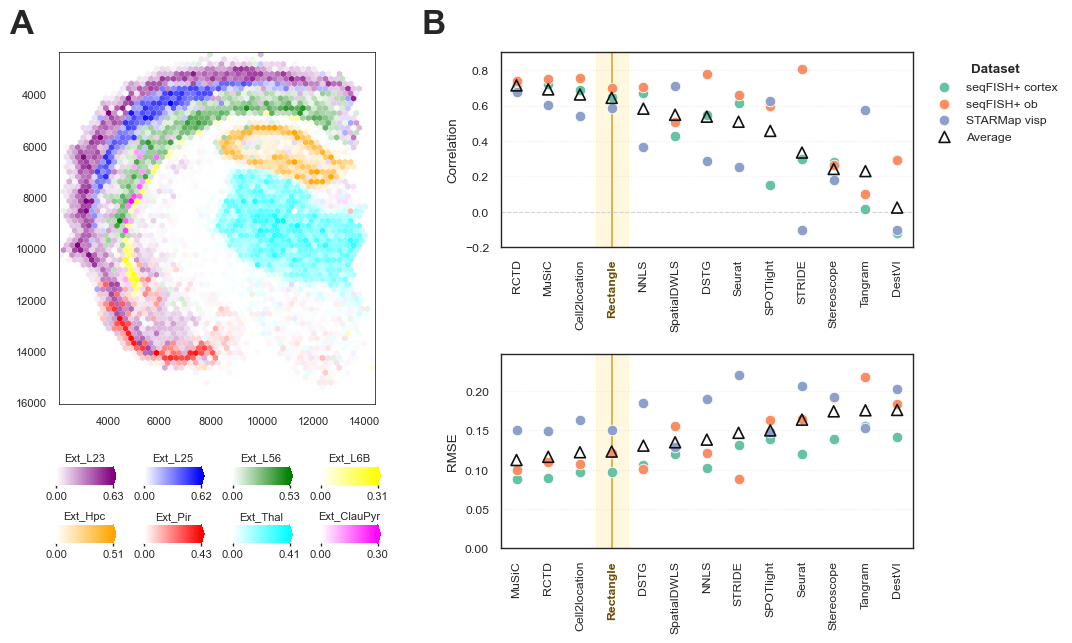

In [16]:
# Combined Figure 5: A spatial map of excitatory-neuron fractions, B Spotless benchmark per method
# Run the Spotless cell (method_dataset_df) and the Figure 5A cell (draw_spatial_panel) first.
import numpy as np
import matplotlib.pyplot as plt

required_vars = ['method_dataset_df', 'method_dataset_order', 'dataset_order', 'dataset_palette', 'draw_spatial_panel']
missing_vars = [var for var in required_vars if var not in globals()]
if missing_vars:
    raise NameError(f'Run the Spotless and Figure 5A cells first. Missing: {missing_vars}')


def draw_method_dataset_metric(ax, metric_col, y_label, legend=True):
    # Same ordering and styling as plot_method_dataset_metric
    avg_metric = method_dataset_df.groupby('Method')[metric_col].mean()
    metric_order = avg_metric.reindex(method_dataset_order).sort_values(ascending=metric_col == 'RMSE').index.tolist()
    rect_idx = metric_order.index('Rectangle')
    ax.axvspan(rect_idx - 0.5, rect_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
    ax.axvline(rect_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

    x = np.arange(len(metric_order), dtype=float)
    for dataset in dataset_order:
        sub = method_dataset_df[method_dataset_df['Dataset'] == dataset].set_index('Method')
        ax.scatter(x, [sub.loc[m, metric_col] if m in sub.index else np.nan for m in metric_order], s=58,
                   color=dataset_palette[dataset], edgecolor='white', linewidth=0.6, label=dataset, zorder=3)
    ax.scatter(x, [avg_metric.loc[m] for m in metric_order], s=62, marker='^', facecolors='none',
               edgecolors='#111111', linewidths=1.2, label='Average', zorder=4)

    if metric_col == 'Correlation':
        ax.axhline(0, linestyle='--', color='lightgrey', linewidth=0.8, zorder=1)
        ax.set_ylim(-0.2, 0.9)
        ax.set_yticks(np.linspace(-0.2, 0.8, 6))
    else:
        metric_max = float(max(method_dataset_df[metric_col].max(), avg_metric.max()))
        ax.set_ylim(0, max(metric_max * 1.12, 0.1))
    ax.set_xlim(-0.5, len(metric_order) - 0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_order, rotation=90)
    ax.get_xticklabels()[rect_idx].set_fontweight('bold')
    ax.get_xticklabels()[rect_idx].set_color('#6b4f00')
    ax.set_ylabel(y_label)
    ax.grid(axis='y', linestyle=':', alpha=0.35)
    if legend:
        leg = ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False, title='Dataset')
        leg.get_title().set_fontweight('bold')


fig = plt.figure(figsize=(10.5, 6.2), facecolor='white')
outer = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.25], wspace=0.32, left=0.04, right=0.86, top=0.92, bottom=0.12)
draw_spatial_panel(fig, outer[0], height_ratios=(3, 0.85), hspace=0.2)
right = outer[1].subgridspec(2, 1, hspace=0.55)
correlation_ax = fig.add_subplot(right[0])
draw_method_dataset_metric(correlation_ax, 'Correlation', 'Correlation', legend=True)
draw_method_dataset_metric(fig.add_subplot(right[1]), 'RMSE', 'RMSE', legend=False)

# B sits just left of panel B's y-axis label, wherever the layout puts it
for letter, x in (('A', 0.0), ('B', correlation_ax.get_position().x0 - 0.075)):
    fig.text(x, 0.99, letter, fontsize=24, fontweight='bold', va='top')

for ext in ('pdf', 'png'):
    fig.savefig(f'../figures/fig4_combined.{ext}', facecolor='white', bbox_inches='tight', dpi=300)
plt.show()
